# Análise univariada

Anotações resumidas das aulas de laboratório do curso Understanding and visualizing data with Python.

https://www.coursera.org/learn/understanding-visualization-data/

Além de conteúdos da aula, também adicionei anotações de dúvidas pessoais e uso de outros comandos, não tratados no curso.

------------------

Sobre analise univariada, não desenvolvi muito a parte textua. Apresento apenas comandos que podem ser úteis para análise exploratória de uma variável e, brevemente, sobre uma variável relacionada com outra.

# Dados NHANES

In [1]:
import pandas as pd
import numpy as np
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from scipy import stats

url = "https://raw.githubusercontent.com/kshedden/statswpy/master/NHANES/merged/nhanes_2015_2016.csv"

df = pd.read_csv(url)

df.head(5)

,SEQN,ALQ101,ALQ110,ALQ130,SMQ020,RIAGENDR,RIDAGEYR,RIDRETH1,DMDCITZN,DMDEDUC2,...,BPXSY2,BPXDI2,BMXWT,BMXHT,BMXBMI,BMXLEG,BMXARML,BMXARMC,BMXWAIST,HIQ210
0,83732,1.0,NaN,1.0,1,1,62,3,1.0,5.0,...,124.0,64.0,94.8,184.5,27.8,43.3,43.6,35.9,101.1,2.0
1,83733,1.0,NaN,6.0,1,1,53,3,2.0,3.0,...,140.0,88.0,90.4,171.4,30.8,38.0,40.0,33.2,107.9,NaN
2,83734,1.0,NaN,NaN,1,1,78,3,1.0,3.0,...,132.0,44.0,83.4,170.1,28.8,35.6,37.0,31.0,116.5,2.0
3,83735,2.0,1.0,1.0,2,2,56,3,1.0,5.0,...,134.0,68.0,109.8,160.9,42.4,38.5,37.7,38.3,110.1,2.0
4,83736,2.0,1.0,1.0,2,2,42,4,1.0,4.0,...,114.0,54.0,55.2,164.9,20.3,37.4,36.0,27.2,80.4,2.0


In [2]:
"""
Busca automaticamente o rótulo (label) de cada coluna de um DataFrame do NHANES 2015-2016,
puxando direto das páginas de codebook do CDC.

Rode isso no seu Colab/Jupyter local (precisa de internet).
"""

import re
import requests

# ---------------------------------------------------------------------
# 1) Carrega o dataset
# ---------------------------------------------------------------------
url = "https://raw.githubusercontent.com/kshedden/statswpy/master/NHANES/merged/nhanes_2015_2016.csv"
df = pd.read_csv(url)

# ---------------------------------------------------------------------
# 2) Mapa de prefixo de coluna -> arquivo de componente do ciclo 2015-2016
#    (o "_I" é o sufixo padrão do CDC para esse ciclo)
# ---------------------------------------------------------------------
PREFIX_TO_FILE = {
    "RIAGENDR": "DEMO_I", "RIDAGEYR": "DEMO_I", "RIDRETH1": "DEMO_I",
    "RIDRETH3": "DEMO_I", "DMDCITZN": "DEMO_I", "DMDEDUC2": "DEMO_I",
    "DMDMARTL": "DEMO_I", "DMDHHSIZ": "DEMO_I", "INDHHIN2": "DEMO_I",
    "INDFMPIR": "DEMO_I", "SDMVPSU": "DEMO_I", "SDMVSTRA": "DEMO_I",
    "WTINT2YR": "DEMO_I", "WTMEC2YR": "DEMO_I", "SEQN": "DEMO_I",
    "BMX": "BMX_I", "BPX": "BPX_I", "ALQ": "ALQ_I", "SMQ": "SMQ_I",
    "HIQ": "HIQ_I", "DIQ": "DIQ_I", "BPQ": "BPQ_I", "PAQ": "PAQ_I",
    "DBQ": "DBQ_I", "MCQ": "MCQ_I", "HUQ": "HUQ_I", "SLQ": "SLQ_I",
    "WHQ": "WHQ_I", "OCQ": "OCQ_I", "INQ": "INQ_I",
}

def find_component_file(col: str) -> str | None:
    """Tenta descobrir o arquivo de codebook certo para uma coluna."""
    if col in PREFIX_TO_FILE:
        return PREFIX_TO_FILE[col]
    # tenta casar pelo prefixo de 3 letras (BMX, BPX, ALQ...)
    for prefix, fname in PREFIX_TO_FILE.items():
        if len(prefix) <= 4 and col.startswith(prefix):
            return fname
    return None

# ---------------------------------------------------------------------
# 3) Faz o parsing de uma página de codebook do CDC e extrai {variável: label}
# ---------------------------------------------------------------------
_cache: dict[str, dict[str, str]] = {}

def get_labels_for_file(component_file: str) -> dict[str, str]:
    if component_file in _cache:
        return _cache[component_file]

    page_url = f"https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2015/DataFiles/{component_file}.htm"
    resp = requests.get(page_url, timeout=20)
    resp.raise_for_status()

    # cada bloco tem: "Variable Name:\nXXXX\nSAS Label:\nYYYY"
    pattern = re.compile(
        r"Variable Name:\s*([A-Z0-9_]+)\s*SAS Label:\s*(.+?)\s*(?:English Text:|Target:)",
        re.DOTALL,
    )
    text = re.sub(r"<[^>]+>", "\n", resp.text)  # remove tags HTML de forma simples
    text = re.sub(r"\n{2,}", "\n", text)

    labels = {m.group(1): m.group(2).strip() for m in pattern.finditer(text)}
    _cache[component_file] = labels
    return labels

# ---------------------------------------------------------------------
# 4) Monta o dicionário final para todas as colunas do seu df
# ---------------------------------------------------------------------
resultado = []
for col in df.columns:
    fname = find_component_file(col)
    label = None
    if fname:
        try:
            label = get_labels_for_file(fname).get(col)
        except requests.RequestException:
            label = None
    resultado.append({"coluna": col, "arquivo_cdc": fname, "significado": label or "não encontrado"})

dicionario = pd.DataFrame(resultado)
print(dicionario.to_string(index=False))

# opcional: salvar em markdown
dicionario.to_markdown("dicionario_colunas.md", index=False)

  coluna arquivo_cdc                              significado
    SEQN      DEMO_I               Respondent sequence number
  ALQ101       ALQ_I     Had at least 12 alcohol drinks/1 yr?
  ALQ110       ALQ_I Had at least 12 alcohol drinks/lifetime?
  ALQ130       ALQ_I Avg # alcoholic drinks/day - past 12 mos
  SMQ020       SMQ_I   Smoked at least 100 cigarettes in life
RIAGENDR      DEMO_I                                   Gender
RIDAGEYR      DEMO_I                Age in years at screening
RIDRETH1      DEMO_I                     Race/Hispanic origin
DMDCITZN      DEMO_I                       Citizenship status
DMDEDUC2      DEMO_I             Education level - Adults 20+
DMDMARTL      DEMO_I                           Marital status
DMDHHSIZ      DEMO_I  Total number of people in the Household
WTINT2YR      DEMO_I      Full sample 2 year interview weight
 SDMVPSU      DEMO_I               Masked variance pseudo-PSU
SDMVSTRA      DEMO_I           Masked variance pseudo-stratum
INDFMPIR

In [3]:
siglas = "SEQN, ALQ101, ALQ110, ALQ130, SMQ020, RIAGENDR, RIDAGEYR, RIDRETH1, DMDCITZN, DMDEDUC2, DMDMARTL, DMDHHSIZ, WTINT2YR, SDMVPSU, SDMVSTRA, INDFMPIR, BPXSY1, BPXDI1, BPXSY2, BPXDI2, BMXWT, BMXHT, BMXBMI, BMXLEG, BMXARML, BMXARMC, BMXWAIST, HIQ210"
descricoes = "Respondent sequence number, Had at least 12 alcohol drinks/1 yr?, Had at least 12 alcohol drinks/lifetime?, Avg qtd. alcoholic drinks/day - past 12 mos, Smoked at least 100 cigarettes in life, Gender, Age in years at screening, Race/Hispanic origin, Citizenship status, Education level - Adults 20+, Marital status, Total number of people in the Household, Full sample 2 year interview weight, Masked variance pseudo-PSU, Masked variance pseudo-stratum, Ratio of family income to poverty, Systolic: Blood pres (1st rdg) mm Hg, Diastolic: Blood pres (1st rdg) mm Hg, Systolic: Blood pres (2nd rdg) mm Hg, Diastolic: Blood pres (2nd rdg) mm Hg, Weight (kg), Standing Height (cm), Body Mass Index (kg/m**2), Upper Leg Length (cm), Upper Arm Length (cm), Arm Circumference (cm), Waist Circumference (cm), Time when no insurance in past year?"

lista_siglas = siglas.split(', ')
lista_descricoes = descricoes.split(', ')
#lista_siglas
#lista_descricoes

dicionario_siglas = dict(zip(lista_siglas, lista_descricoes))

# Vou renomear
df = df.rename(columns = dict(zip(lista_siglas, lista_descricoes)))
df

,Respondent sequence number,Had at least 12 alcohol drinks/1 yr?,Had at least 12 alcohol drinks/lifetime?,Avg qtd. alcoholic drinks/day - past 12 mos,Smoked at least 100 cigarettes in life,Gender,Age in years at screening,Race/Hispanic origin,Citizenship status,Education level - Adults 20+,...,Systolic: Blood pres (2nd rdg) mm Hg,Diastolic: Blood pres (2nd rdg) mm Hg,Weight (kg),Standing Height (cm),Body Mass Index (kg/m**2),Upper Leg Length (cm),Upper Arm Length (cm),Arm Circumference (cm),Waist Circumference (cm),Time when no insurance in past year?
0,83732,1.0,NaN,1.0,1,1,62,3,1.0,5.0,...,124.0,64.0,94.8,184.5,27.8,43.3,43.6,35.9,101.1,2.0
1,83733,1.0,NaN,6.0,1,1,53,3,2.0,3.0,...,140.0,88.0,90.4,171.4,30.8,38.0,40.0,33.2,107.9,NaN
2,83734,1.0,NaN,NaN,1,1,78,3,1.0,3.0,...,132.0,44.0,83.4,170.1,28.8,35.6,37.0,31.0,116.5,2.0
3,83735,2.0,1.0,1.0,2,2,56,3,1.0,5.0,...,134.0,68.0,109.8,160.9,42.4,38.5,37.7,38.3,110.1,2.0
4,83736,2.0,1.0,1.0,2,2,42,4,1.0,4.0,...,114.0,54.0,55.2,164.9,20.3,37.4,36.0,27.2,80.4,2.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5730,93695,2.0,2.0,NaN,1,2,76,3,1.0,3.0,...,112.0,46.0,59.1,165.8,21.5,38.2,37.0,29.5,95.0,2.0
5731,93696,2.0,2.0,NaN,2,1,26,3,1.0,5.0,...,116.0,76.0,112.1,182.2,33.8,43.4,41.8,42.3,110.2,2.0
5732,93697,1.0,NaN,1.0,1,2,80,3,1.0,4.0,...,146.0,58.0,71.7,152.2,31.0,31.3,37.5,28.8,NaN,2.0
5733,93700,NaN,NaN,NaN,1,1,35,3,2.0,1.0,...,106.0,66.0,78.2,173.3,26.0,40.3,37.5,30.6,98.9,2.0


## Alguns métodos

Boa prártica: make copy of the dataframe to protect the original

In [4]:
df_copia = df.copy()

### Atribuíndo texto a variáveis categóricas

In [6]:
estado_civil = dicionario_siglas['DMDMARTL']
estado_civil

'Marital status'

In [7]:
valor_genero = dicionario_siglas['RIAGENDR']
valor_genero

'Gender'

In [8]:
# Agora que descobri o novo rótulo da coluna DMDMARTL, definimos os textos
valores_possiveis_estado_civil = {1: 'Casado', 2: 'Viúvo(a)', 3: 'Divorciado(a)', 4: 'Separado(a)', 5: 'Solteiro(a)', 6: 'Morando junto', 77: 'Recusou responder', 99: 'Não sabe'}

df_copia['Marital status'] = df_copia['Marital status'].replace(valores_possiveis_estado_civil)

valores_possiveis_genero = {1: 'Masculino', 2: 'Feminino'}
df_copia['Gender'] = df_copia['Gender'].replace(valores_possiveis_genero)

### Puxando só uma coluna específica

In [9]:
df_copia.loc[:, 'Marital status']

,Marital status
0,Casado
1,Divorciado(a)
2,Casado
3,Morando junto
4,Divorciado(a)
...,...
5730,Viúvo(a)
5731,Casado
5732,Viúvo(a)
5733,Casado


### Removendo coluna com `.drop()`

#### List comprehension para listar as colunas

In [14]:
siglas_remover = ['BMXLEG', 'BMXARML', 'BMXARMC', 'BMXWAIST', 'HIQ210']

remover_colunas = [dicionario_siglas[sigla] for sigla in siglas_remover]
remover_colunas

['Upper Leg Length (cm)',
 'Upper Arm Length (cm)',
 'Arm Circumference (cm)',
 'Waist Circumference (cm)',
 'Time when no insurance in past year?']

#### `.drop()`

In [15]:
df_copia = df_copia.drop(columns = remover_colunas)
# outra forma, alterando o df_copia diretamente, seria:
# df_copia.drop(columns = remover_colunas, inplace = True)

## Tabelas de frequência

In [4]:
#df.DMDEDUC2.value_counts()
df['Education level - Adults 20+'].value_counts()

,count
Education level - Adults 20+,
4.0,1621
5.0,1366
3.0,1186
1.0,655
2.0,643
9.0,3


Note que o método value_counts() não exibe os valores faltantes.

Dá para confirmar isso somando os valores que saíram acima e comparando com o número total de linas do dataset df.

In [5]:
df.shape

(5735, 28)

In [6]:
print(df['Education level - Adults 20+'].value_counts().sum())

5474


Outra forma de obter esse resultado é localizando os valores faltantes e contando:

In [7]:
#pd.isnull(df.DMDEDUC2).sum()
pd.isnull(df['Education level - Adults 20+']).sum()

np.int64(261)

### Acesso a colunas

Considere, para fins de exemplo, a coluna Gender do df.

No pandas, df["Gender"] e df.Gender acessam a mesma coluna do DataFrame df (quando o nome é válido como atributo), mas têm diferenças práticas importantes de sintaxe, segurança e uso.


- df["Gender"] (indexação por colchetes / chave): acessa a coluna como se fosse a **chave** de um dicionário. Funciona sempre (ex.: df["Nível de escolaridade"]).

- df["Gender"] (acesso por atributo / ponto): acessa a coluna como um **atributo** do objeto DataFrame. Dá erro de sintaxe se o nome tiver espaços, traços, acentos problemáticos ou começar com número.

### Atribuindo valores legíveis à variáveis

Em alguns casos, pode ser útil substituir valores inteiros para um texto que reflita o significado da variável, que pode ser recebido valores inteiros para indicar valores categóricos.

In [8]:
df['Nível de escolaridade'] = df['Education level - Adults 20+'].replace( {1: '< 9', 2: '9 - 11', 3: 'HS/GED', 4: 'Alguma faculdade', 5: 'Faculdade',
                                       7: 'Recusaram responder', 9: 'Não sabem' } )
df['Nível de escolaridade'].value_counts()

,count
Nível de escolaridade,
Alguma faculdade,1621
Faculdade,1366
HS/GED,1186
< 9,655
9 - 11,643
Não sabem,3


Fazendo o mesmo para a variável gênero.

In [9]:
df['Gênero'] = df['Gender'].replace( {1: 'Masculino', 2: 'Feminino'} )

### Proporção de uma amostra

In [10]:
x = df['Gênero'].value_counts()
x / x.sum()

,count
Gênero,
Feminino,0.518919
Masculino,0.481081


Às vezes, será necessário atribuir um rótulo/nome a valores do tipo NaN para saber a proporção desses dados na amostra. Façamos o seguinte:

In [21]:
df['Nível de escolaridade'] = df['Education level - Adults 20+'].fillna('Valores faltantes')
x = df['Nível de escolaridade'].value_counts()
x / x.sum()

,count
Nível de escolaridade,
4.0,0.282650
5.0,0.238187
3.0,0.206800
1.0,0.114211
2.0,0.112119
Valores faltantes,0.045510
9.0,0.000523


## Resumos numéricos

In [13]:
df['Weight (kg)'].dropna().describe()

,Weight (kg)
count,5666.000000
mean,81.342676
std,21.764409
min,32.400000
25%,65.900000
50%,78.200000
75%,92.700000
max,198.900000


In [18]:
valor = dicionario_siglas['BMXWT']
valor

'Weight (kg)'

Fazendo o resumo numérico com métodos do Pandas e do Numpy.

In [20]:
x = df['Weight (kg)'].dropna() # removendo todos os valores faltantes

# pelo método do Pandas
print('Resumos numéricos pelo Pandas')
print(x.mean())
print(x.median())
print(x.quantile(0.75))

print('\nResumos numéricos pelo Numpy')
print(np.mean(x)) # média pelo método do Numpy
print(np.percentile(x, 50))
print(np.percentile(x, 75))

Resumos numéricos pelo Pandas
81.34267560889516
78.2
92.7

Resumos numéricos pelo Numpy
81.34267560889516
78.2
92.7


A seguir, analisamos as frequências de uma medição da pressão arterial sistólica (BPXSY1).

Aqui, "BPX" é o prefixo do NHANES para medições de pressão arterial, "SY" significa pressão arterial "sistólica" (a pressão arterial no pico de um ciclo de batimento cardíaco) e "1" indica que esta é a primeira de três medições de pressão arterial sistólica realizadas em um indivíduo.

Geralmente, considera-se que uma pessoa tem pré-hipertensão quando sua pressão arterial sistólica está entre 120 e 139, ou quando sua pressão arterial diastólica está entre 80 e 89. Considerando apenas a condição sistólica, podemos calcular a proporção da amostra do NHANES que seria considerada pré-hipertensa.

In [26]:
p_sis_1 = dicionario_siglas['BPXSY1']
p_sis_1

#np.mean( (df['Systolic: Blood pres (1st rdg) mm Hg'] >= 120) & (df['Systolic: Blood pres (1st rdg) mm Hg'] <= 139) )
np.mean( (df[p_sis_1] >= 120) & (df[p_sis_1] <= 139) )

np.float64(0.366870095902354)

## Resumos gráficos

In [32]:
print(f'Variável BPXSY1:  {dicionario_siglas['BPXSY1']}')
print(f'Variável BPXSY2:  {dicionario_siglas['BPXSY2']}')
print(f'Variável BPXDI1:  {dicionario_siglas['BPXDI1']}')
print(f'Variável BPXDI2:  {dicionario_siglas['BPXDI2']}')

Variável BPXSY1:  Systolic: Blood pres (1st rdg) mm Hg
Variável BPXSY2:  Systolic: Blood pres (2nd rdg) mm Hg
Variável BPXDI1:  Diastolic: Blood pres (1st rdg) mm Hg
Variável BPXDI2:  Diastolic: Blood pres (2nd rdg) mm Hg


Variável BPXSY1:  Systolic: Blood pres (1st rdg) mm Hg


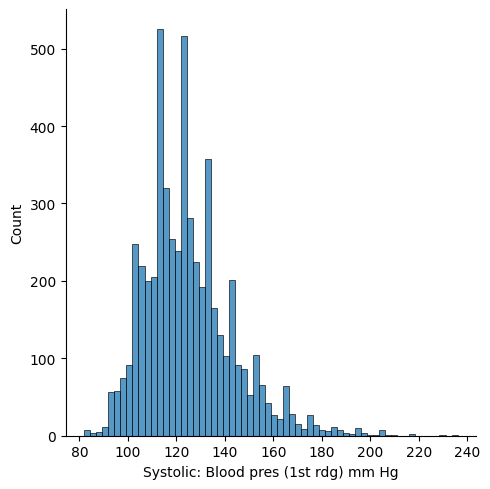

In [31]:
sns.displot(df['Systolic: Blood pres (1st rdg) mm Hg'].dropna())

([0, 1, 2, 3],
 [Text(0, 0, 'Systolic: Blood pres (1st rdg) mm Hg'),
  Text(1, 0, 'Systolic: Blood pres (2nd rdg) mm Hg'),
  Text(2, 0, 'Diastolic: Blood pres (1st rdg) mm Hg'),
  Text(3, 0, 'Diastolic: Blood pres (2nd rdg) mm Hg')])

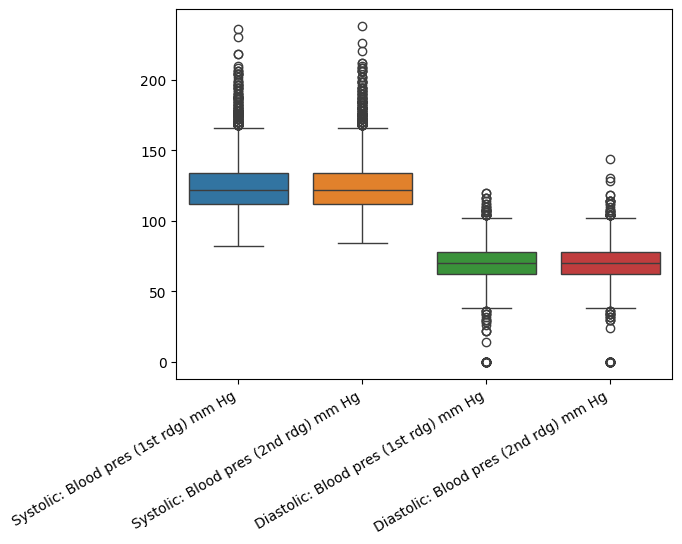

In [35]:
bp = sns.boxplot(data = df.loc[:, ['Systolic: Blood pres (1st rdg) mm Hg', 'Systolic: Blood pres (2nd rdg) mm Hg', 'Diastolic: Blood pres (1st rdg) mm Hg', 'Diastolic: Blood pres (2nd rdg) mm Hg'] ] )
#_ = bp.set_ylabel('Pressão sanguínea em mm/Hg')
# métodos tipo bp.set_ylabel(...) retornam um objeto (geralmente um objeto Text ou Axes).
# Ao escrever _ = bp.set_ylabel(...), guarda-se esse retorno em _ apenas para evitar que essa linha extra apareça poluindo a saída do gráfico

plt.xticks(rotation = 30, ha = 'right')

## Estratificação

Uma das formas mais eficazes de obter informações sobre um data set é dividi-lo em datasets menores, mais uniformes, e analiza-los em 'estrados'.

In [4]:
#dicionario_siglas['RIDAGEYR']
dicionario_siglas['BPXSY1']

'Systolic: Blood pres (1st rdg) mm Hg'

Text(0.5, 1.0, 'Boxplot da pressão sistólica 1 estratificada por grupos de idade')

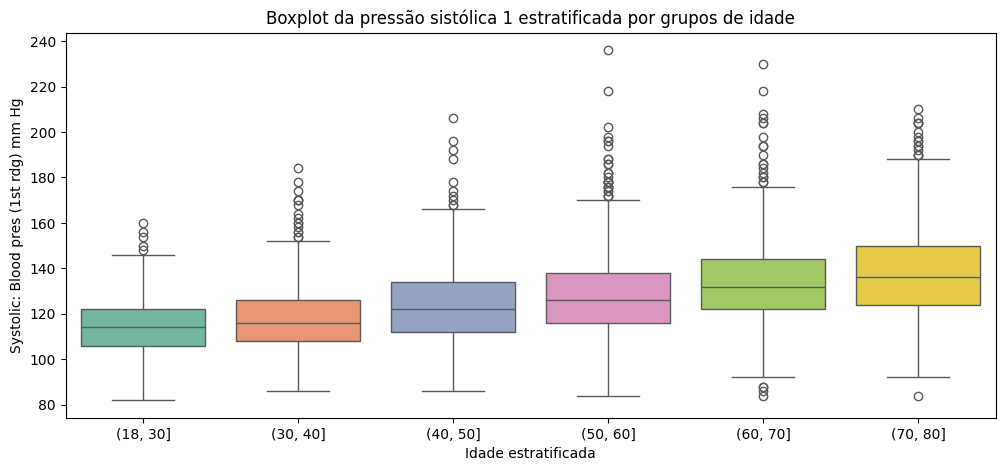

In [16]:
# criando uma estratificação de idades baseada nos valores listados (que podem ser valores de interesse, a depender da pesquisa)
df['Idade estratificada'] = pd.cut(df['Age in years at screening'], [18, 30, 40, 50, 60, 70, 80])

plt.figure(figsize = (12, 5))
sns.boxplot(x = 'Idade estratificada', y = 'Systolic: Blood pres (1st rdg) mm Hg', hue = 'Idade estratificada', data = df, palette = 'Set2', legend = False).set_title('Boxplot da pressão sistólica 1 estratificada por grupos de idade')
#hue = 'Idade estratificada' e legend = False fazem cada boxplot sair de uma cor diferente
# coloquei palette = 'Set2' pra ficar uma paleta que gosto, mas é opcional essa parte

Parece que a pressão sistólica 1 cresce com a idade.

Adicionando mais uma camada: olhando por gênero.

Text(0.5, 1.0, 'Boxplot da pressão sistólica 1 estratificada por grupos de idade e gênero')

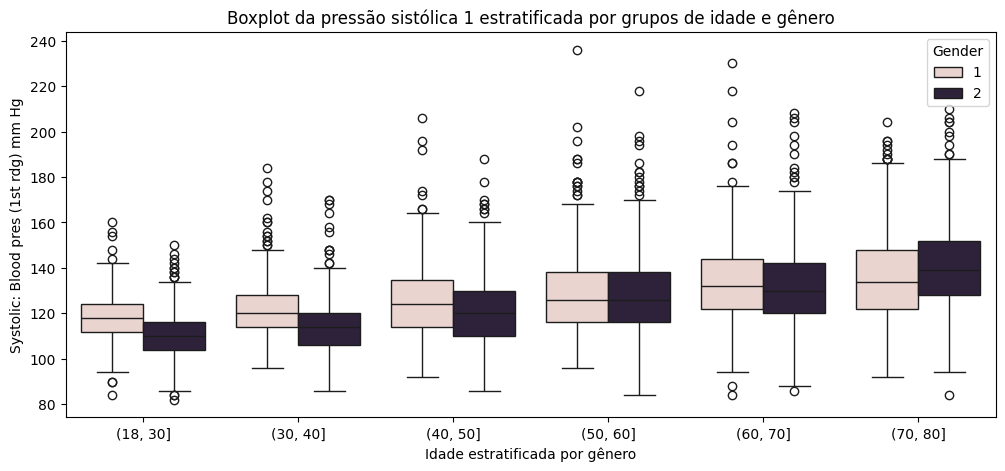

In [10]:
df['Idade estratificada por gênero'] = pd.cut(df['Age in years at screening'], [18, 30, 40, 50, 60, 70, 80])

plt.figure(figsize = (12, 5))
sns.boxplot(x = df['Idade estratificada por gênero'], y = df['Systolic: Blood pres (1st rdg) mm Hg'], hue = 'Gender', data = df).set_title('Boxplot da pressão sistólica 1 estratificada por grupos de idade e gênero')

### Agrupamentos em uma estratificação

In [19]:
df['Gênero'] = df['Gender'].replace({1: 'Masculino', 2: 'Feminino'})

<Axes: xlabel='Gênero', ylabel='Systolic: Blood pres (1st rdg) mm Hg'>

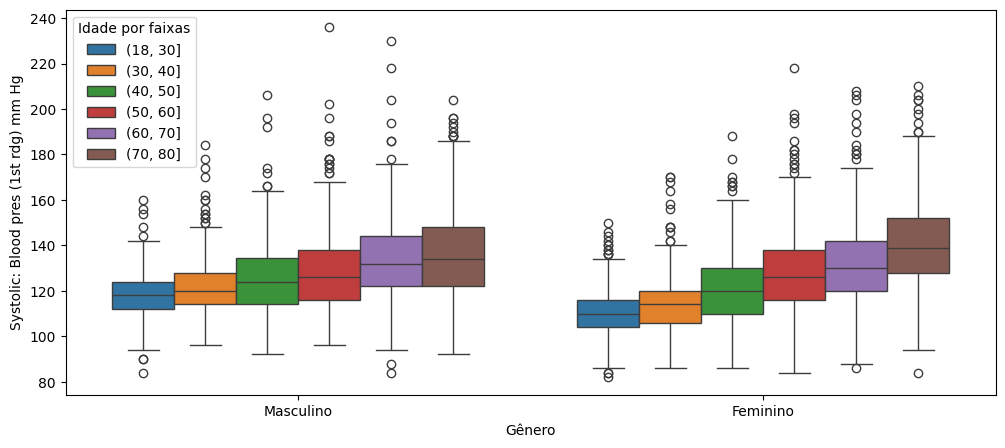

In [20]:
df['Idade por faixas'] = pd.cut(df['Age in years at screening'], [18, 30, 40, 50, 60, 70, 80])
plt.figure(figsize = (12, 5))
sns.boxplot(x= 'Gênero', y = 'Systolic: Blood pres (1st rdg) mm Hg', hue = 'Idade por faixas', data = df)

Nota sobre causalidade, confundimento e efeito de coorte:
Um dos papéis mais importantes da estatística não é apenas mostrar que existem diferenças entre grupos, mas ajudar os pesquisadores a descobrir as verdadeiras causas por trás dessas diferenças, evitando interpretações enganosas.
Na análise anterior, observamos que tanto a pressão arterial quanto o nível de escolaridade variam de acordo com a idade. No entanto, a relação de causa e efeito é completamente diferente nos dois casos:

• Causalidade direta (Pressão arterial): É perfeitamente plausível que o envelhecimento biológico cause diretamente o aumento da pressão arterial (devido ao enrijecimento natural dos vasos sanguíneos ao longo dos anos, por exemplo).

• Fator de confundimento e Efeito de Coorte (Escolaridade): Seria um erro concluir que "envelhecer faz a escolaridade diminuir". Aqui, a idade atua como um fator de confundimento — uma variável que parece ser a causa, mas que, na verdade, está apenas ligada ao verdadeiro motivo da diferença: o efeito de coorte de nascimento.

O que é o efeito de coorte de nascimento?

Na estatística e na epidemiologia, uma coorte é um grupo de pessoas que compartilham uma característica em comum — neste caso, terem nascido na mesma época (geração). O efeito de coorte ocorre quando os resultados observados em um grupo são consequência das condições históricas, sociais ou culturais específicas da época em que aquelas pessoas cresceram, e não do processo biológico de envelhecer.

Como isso aparece nos dados da pesquisa (NHANES):

A NHANES é uma pesquisa transversal, o que significa que ela funciona como uma "fotografia": todos os dados de uma etapa são coletados em um único momento no tempo, comparando pessoas de diferentes idades simultaneamente (em vez de acompanhar as mesmas pessoas ao longo de décadas).

• Quem tinha 65 anos em 2015 (ano da coleta) estava na idade de entrar na faculdade por volta de 1970, uma época em que o ensino superior era muito mais restrito e menos acessível.

• Já quem estava na casa dos 20 anos em 2015 chegou à idade universitária por volta de 2010 ou depois, quando o acesso às universidades já havia se expandido enormemente.

Portanto, os mais jovens apresentam hoje um nível de escolaridade maior não porque "ser jovem dá mais estudo", mas porque nasceram em uma geração com muito mais oportunidades educacionais. Como esse efeito está ligado à geração e não à idade biológica, quando esses jovens de 20 anos chegarem aos 65, eles levarão seus diplomas com eles — e o retrato da relação entre idade e escolaridade nas pesquisas futuras será bem diferente do atual.

In [25]:
# Em algum momento acima, inserimos o valor 'Valores faltantes' para se referir e contar os dados faltantes. Dessa forma, a coluna Nível de escolaridade está com valores mistos: inteiros (que se referem
# as níveis e a string Valores faltantes). Para evitar erro, precisamos padronizar

df['Nível de escolaridade'] = df['Nível de escolaridade'].fillna('Valores faltantes').astype(str)
df['Nível de escolaridade'].unique()

array(['5.0', '3.0', '4.0', '2.0', 'Valores faltantes', '1.0', '9.0'],
      dtype=object)

In [28]:
df['Nível de escolaridade'] = df['Education level - Adults 20+'].replace( {1: '< 9', 2: '9 - 11', 3: 'HS/GED', 4: 'Alguma faculdade', 5: 'Faculdade',
                                       7: 'Recusaram responder', 9: 'Não sabem' } )
df['Nível de escolaridade'].value_counts()

,count
Nível de escolaridade,
Alguma faculdade,1621
Faculdade,1366
HS/GED,1186
< 9,655
9 - 11,643
Não sabem,3


In [29]:
df.groupby('Idade por faixas', observed = False)['Nível de escolaridade'].value_counts()

Idade por faixas  Nível de escolaridade
(18, 30]          Alguma faculdade         364
                  Faculdade                278
                  HS/GED                   237
                  9 - 11                    99
                  < 9                       47
                  Não sabem                  0
(30, 40]          Alguma faculdade         282
                  Faculdade                264
                  HS/GED                   182
                  9 - 11                   111
                  < 9                       93
                  Não sabem                  0
(40, 50]          Alguma faculdade         262
                  Faculdade                260
                  HS/GED                   171
                  9 - 11                   112
                  < 9                       98
                  Não sabem                  0
(50, 60]          Alguma faculdade         258
                  Faculdade                220
                  HS/GED                   220
                  9 - 11                   122
                  < 9                      104
                  Não sabem                  0
(60, 70]          Alguma faculdade         238
                  HS/GED                   192
                  Faculdade                188
                  < 9                      149
                  9 - 11                   111
                  Não sabem                  0
(70, 80]          Alguma faculdade         217
                  HS/GED                   184
                  < 9                      164
                  Faculdade                156
                  9 - 11                    88
                  Não sabem                  3
Name: count, dtype: int64

### Parâmetro observed = False no groupby()

No pandas, o parâmetro observed=False no groupby() serve para controlar como o agrupamento lida com categorias que não aparecem de facto nos dados quando a coluna agrupada é do tipo Categorical (como costuma acontecer com colunas criadas por pd.cut(), tal como 'Idade por faixas').  

O que acontece na prática?

Imagine que criou faixas etárias com pd.cut(), mas na faixa dos 80–90 anos não há nenhum registo no df:observed=False (mantém categorias vazias): o pandas inclui todas as categorias definidas no tipo categórico, mesmo aquelas sem ocorrências (mostrando 0 ou omitindo linhas sem contagem conforme a operação), preservando a estrutura completa das faixas.observed=True (apenas categorias observadas): o pandas considera apenas as categorias que têm pelo menos um registo presente nos dados.

Por que o aviso (FutureWarning) aparecia?

Em versões mais antigas do pandas, o padrão era observed=False (o que em colunas categóricas grandes podia gerar combinações vazias desnecessárias). O pandas avisou que no futuro o padrão passará a ser observed=True, pedindo para explicitar o valor desejado.  

Também podemos estratificar conjuntamente por idade e gênero para explorar como o nível de escolaridade varia de acordo com ambos os fatores simultaneamente. Ao fazer isso, fica mais fácil interpretar os resultados se transformarmos os níveis de escolaridade em colunas (tabela dinâmica/pivô) e normalizarmos as contagens para que somem 1. Depois disso, os resultados podem ser interpretados como proporções ou probabilidades. Uma observação notável dessa tabela é que, para pessoas com até cerca de 60 anos, as mulheres têm maior probabilidade de terem concluído o ensino superior do que os homens, mas, para pessoas com mais de 60 anos, essa relação se inverte.

Vamos:

- filtrar a coluna 'Nível de escolaridade' (removendo 'Valores faltantes' e 'Não sabem');

- agrupar por 'Idade por faixas' e 'Gênero';

- contar as ocorrências;

- transformar o resultado numa tabela de proporções.

In [35]:
dx = df.loc[~df['Nível de escolaridade'].isin(['Valores faltantes', 'Não sabem']), :] # eliminando valores faltantes/não sabem
dx = dx.groupby(['Idade por faixas', 'Gênero'], observed = False)['Nível de escolaridade']
dx = dx.value_counts()
dx = dx.unstack()
dx = dx.apply(lambda x: x/x.sum(), axis = 1) # normaliza com cada estrado para obter proporções
print(dx.to_string(float_format = '%.3f'))

Nível de escolaridade       9 - 11   < 9  Alguma faculdade  Faculdade  HS/GED
Idade por faixas Gênero                                                      
(18, 30]         Feminino    0.080 0.049             0.374      0.282   0.215
                 Masculino   0.117 0.042             0.333      0.258   0.250
(30, 40]         Feminino    0.089 0.097             0.335      0.314   0.165
                 Masculino   0.151 0.103             0.269      0.251   0.227
(40, 50]         Feminino    0.110 0.106             0.313      0.299   0.173
                 Masculino   0.142 0.112             0.262      0.274   0.209
(50, 60]         Feminino    0.117 0.102             0.302      0.245   0.234
                 Masculino   0.148 0.123             0.256      0.231   0.242
(60, 70]         Feminino    0.118 0.188             0.293      0.195   0.206
                 Masculino   0.135 0.151             0.249      0.233   0.231
(70, 80]         Feminino    0.105 0.225             0.281      

/tmp/ipykernel_2140/3425211408.py:2: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  dx = dx.groupby(['Idade por faixas', 'Gênero'])['Nível de escolaridade']


# Dados catwheeel

In [ ]:
url_cartwheel = "https://raw.githubusercontent.com/tamalmuk21/Stat_with_python/master/stat/Cartwheeldata.csv"
df_graph = pd.read_csv(url_cartwheel)
df_graph.head()